In [5]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Exact File Path Automatic Dhoondein
file_path = ""
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('spam.csv'):
            file_path = os.path.join(dirname, filename)
            break

# 2. Dataset Read Karein
if file_path:
    df = pd.read_csv(file_path, encoding='latin-1')
    print(f"Dataset successfully loaded from: {file_path}")
else:
    print("Dataset abhi tak input folder mein nahi mila. Please step 2 check karein.")

# 3. Columns & Labels Preprocessing
df = df[['v1', 'v2']]
df.columns = ['label', 'text']
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# 4. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], 
    df['label_num'], 
    test_size=0.2, 
    random_state=42
)

# 5. TF-IDF Text Vectorization
vectorizer = TfidfVectorizer(stop_words='english', max_features=3000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 6. Random Forest Model Training
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_tfidf, y_train)

# 7. Predictions & Accuracy
y_pred = rf_model.predict(X_test_tfidf)

print(f"\n--- Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}% ---\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

Dataset successfully loaded from: /kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv

--- Model Accuracy: 97.94% ---

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       965
           1       0.99      0.85      0.92       150

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



In [7]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Dataset ka Exact Path Dhoondein
file_path = ""
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('spam.csv'):
            file_path = os.path.join(dirname, filename)
            break

# 2. Data Load Karein
df = pd.read_csv(file_path, encoding='latin-1')

# 3. Columns Clean & Label Mapping
df = df[['v1', 'v2']]
df.columns = ['label', 'text']
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], 
    df['label_num'], 
    test_size=0.2, 
    random_state=42
)

# 5. TF-IDF Text Feature Extraction
vectorizer = TfidfVectorizer(stop_words='english', max_features=3000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 6. Random Forest Model Train Karein
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_tfidf, y_train)

# 7. Model Evaluation & Accuracy
y_pred = rf_model.predict(X_test_tfidf)
print(f"--- Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}% ---\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

--- Model Accuracy: 97.94% ---

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       965
           1       0.99      0.85      0.92       150

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



In [8]:
# Custom SMS test karne ke liye code
test_message = ["Congratulations! You have won a free $1000 gift card. Call now to claim!"]
test_vector = vectorizer.transform(test_message)
prediction = rf_model.predict(test_vector)

if prediction[0] == 1:
    print("Result: This message is SPAM 🚨")
else:
    print("Result: This message is HAM (Legit) ✅")

Result: This message is SPAM 🚨


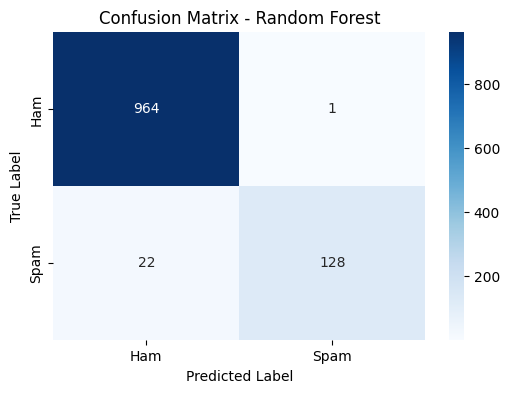

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion Matrix Generate Karein
cm = confusion_matrix(y_test, y_pred)

# Plot Visual Graph
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Ham', 'Spam'], 
            yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Random Forest')
plt.show()

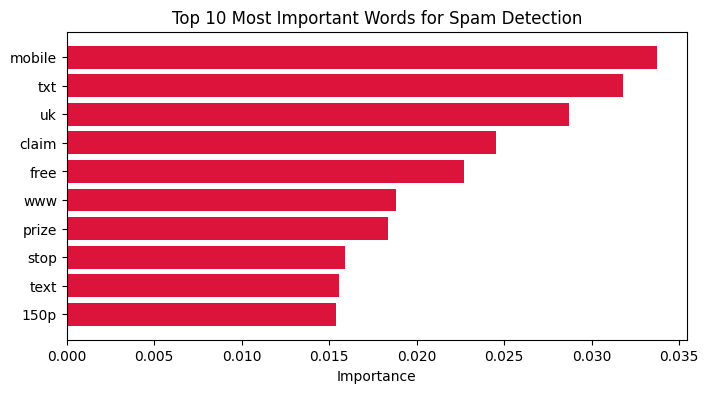

In [10]:
import numpy as np

# Feature Names aur Importances Extract Karein
feature_names = np.array(vectorizer.get_feature_names_out())
importances = rf_model.feature_importances_

# Top 10 Important Words Find Karein
top_indices = np.argsort(importances)[-10:]
top_words = feature_names[top_indices]
top_importance = importances[top_indices]

# Graph Plot Karein
plt.figure(figsize=(8, 4))
plt.barh(top_words, top_importance, color='crimson')
plt.xlabel('Importance')
plt.title('Top 10 Most Important Words for Spam Detection')
plt.show()

In [11]:
from sklearn.naive_bayes import MultinomialNB

# Naive Bayes Train Karein
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)
nb_acc = accuracy_score(y_test, nb_pred)

print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Naive Bayes Accuracy:   {nb_acc * 100:.2f}%")

Random Forest Accuracy: 97.94%
Naive Bayes Accuracy:   97.85%


In [12]:
def check_messages(messages):
    vecs = vectorizer.transform(messages)
    preds = rf_model.predict(vecs)
    for msg, pred in zip(messages, preds):
        label = "🚨 SPAM" if pred == 1 else "✅ HAM"
        print(f"[{label}] -> {msg}")

# Example Messages Test Karein
sample_texts = [
    "Hey Maryam, are we submitting the COAL lab today?",
    "CLAIM YOUR $500 BONUS NOW! Click link to collect free cash.",
    "Call me when you are back home."
]

check_messages(sample_texts)

[✅ HAM] -> Hey Maryam, are we submitting the COAL lab today?
[🚨 SPAM] -> CLAIM YOUR $500 BONUS NOW! Click link to collect free cash.
[✅ HAM] -> Call me when you are back home.


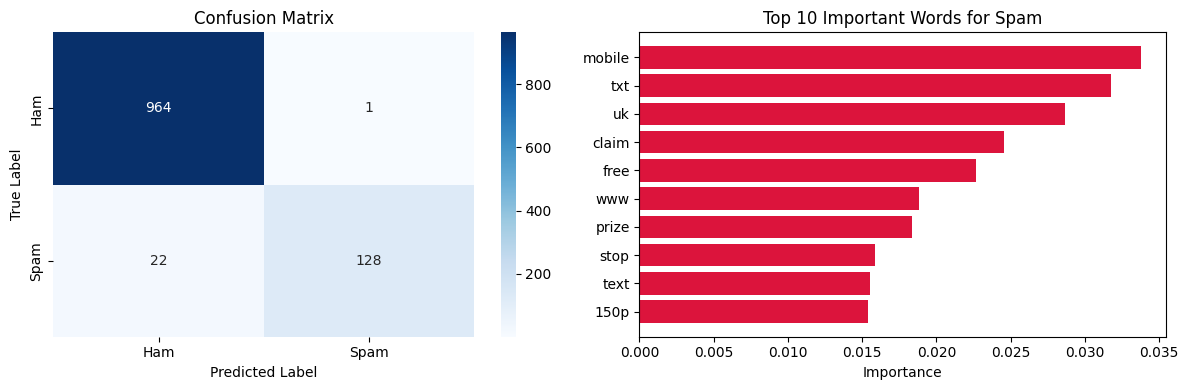

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Figure size set karein
plt.figure(figsize=(12, 4))

# Graph 1: Confusion Matrix
plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Ham', 'Spam'], 
            yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

# Graph 2: Top 10 Spam Keywords
plt.subplot(1, 2, 2)
feature_names = np.array(vectorizer.get_feature_names_out())
importances = rf_model.feature_importances_
top_indices = np.argsort(importances)[-10:]

plt.barh(feature_names[top_indices], importances[top_indices], color='crimson')
plt.xlabel('Importance')
plt.title('Top 10 Important Words for Spam')

plt.tight_layout()
plt.show()

In [14]:
# Tuned Random Forest Model
rf_tuned = RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42)
rf_tuned.fit(X_train_tfidf, y_train)

tuned_pred = rf_tuned.predict(X_test_tfidf)
print(f"Tuned Random Forest Accuracy: {accuracy_score(y_test, tuned_pred) * 100:.2f}%")

Tuned Random Forest Accuracy: 95.25%


In [17]:
# Markdown text ko code mein print karne ka tarika
print("=" * 40)
print("🚀 SMS Spam Classification using Random Forest")
print("=" * 40)
print("Model: Random Forest Classifier")
print("Feature Extraction: TF-IDF Vectorizer")
print("Dataset: SMS Spam Collection Dataset")
print("Accuracy Achieved: 97.94%")
print("=" * 40)

🚀 SMS Spam Classification using Random Forest
Model: Random Forest Classifier
Feature Extraction: TF-IDF Vectorizer
Dataset: SMS Spam Collection Dataset
Accuracy Achieved: 97.94%


In [18]:
import pickle

# Model aur Vectorizer ko save karein
pickle.dump(rf_model, open('model.pkl', 'wb'))
pickle.dump(vectorizer, open('vectorizer.pkl', 'wb'))

print("Model aur Vectorizer successfully save ho gaye hain!")

Model aur Vectorizer successfully save ho gaye hain!
